In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
df = pd.read_csv("emergency_service.csv") # Data Loading
df.head()

,Timestamp,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,Road_Type,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time
0,01/01/2018 00:00,Low,Cardiac Arrest,Suburban,High,Clear,Available,91,8.89,1,Unavailable,Highway,Major,43.549849,90.030756,Severe,AI,20.870220
1,01/01/2018 00:10,Low,Other,Urban,Moderate,Clear,Available,28,28.10,2,Unavailable,Highway,Critical,30.687975,88.255008,Moderate,Human,24.486195
2,01/01/2018 00:20,Medium,Cardiac Arrest,Suburban,High,Rainy,Available,83,40.43,1,Unavailable,Unpaved Road,Minor,44.456331,97.719622,No Impact,Human,18.760740
3,01/01/2018 00:30,Low,Accident,Urban,Moderate,Clear,Available,31,18.97,3,Available,Highway,Minor,35.879968,60.234672,No Impact,Human,18.169534
4,01/01/2018 00:40,Low,Cardiac Arrest,Urban,Moderate,Stormy,Available,52,16.31,3,Available,Highway,Minor,26.369383,71.083564,Moderate,Human,5.000000


In [52]:
# Dataset Overview
df.shape

(368065, 18)

In [21]:
df.info() # helps us to see the categorical columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 368065 entries, 0 to 368064
Data columns (total 18 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Timestamp                368065 non-null  object 
 1   Incident_Severity        368065 non-null  object 
 2   Incident_Type            368065 non-null  object 
 3   Region_Type              368065 non-null  object 
 4   Traffic_Congestion       368065 non-null  object 
 5   Weather_Condition        368065 non-null  object 
 6   Ambulance_Availability   368065 non-null  object 
 7   Hospital_Capacity        368065 non-null  int64  
 8   Distance_to_Incident     368065 non-null  float64
 9   Number_of_Injuries       368065 non-null  int64  
 10  Specialist_Availability  368065 non-null  object 
 11  Road_Type                368065 non-null  object 
 12  Emergency_Level          368065 non-null  object 
 13  Ambulance_Speed          368065 non-null  float64
 14  Fuel

In [55]:
df.isnull().sum() # Missing Values

Timestamp                  0
Incident_Severity          0
Incident_Type              0
Region_Type                0
Traffic_Congestion         0
Weather_Condition          0
Ambulance_Availability     0
Hospital_Capacity          0
Distance_to_Incident       0
Number_of_Injuries         0
Specialist_Availability    0
Road_Type                  0
Emergency_Level            0
Ambulance_Speed            0
Fuel_Level                 0
Weather_Impact             0
Dispatch_Coordinator       0
Response_Time              0
dtype: int64

In [57]:
duplicate_count = df.duplicated().sum() # Duplicate Records

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [58]:
df.describe() # Summary Statistics

,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Ambulance_Speed,Fuel_Level,Response_Time
count,368065.000000,368065.000000,368065.000000,368065.000000,368065.000000,368065.000000
mean,54.496809,25.460655,1.520987,40.007905,69.867314,15.057149
std,25.980503,14.152281,0.728015,7.953883,14.681359,4.890373
min,10.000000,1.000000,1.000000,20.000000,10.000000,5.000000
25%,32.000000,13.180000,1.000000,34.590985,59.871995,11.649407
50%,54.000000,25.440000,1.000000,39.998567,70.003675,15.009103
75%,77.000000,37.720000,2.000000,45.396200,80.057268,18.381593
max,99.000000,50.000000,4.000000,77.801028,100.000000,30.000000


In [23]:
print("Mean:", df["Response_Time"].mean())
print("Median:", df["Response_Time"].median())
print("Min:", df["Response_Time"].min())
print("Max:", df["Response_Time"].max())
print("Std:", df["Response_Time"].std())

Mean: 15.057149184210854
Median: 15.00910315
Min: 5.0
Max: 30.0
Std: 4.890373203851171


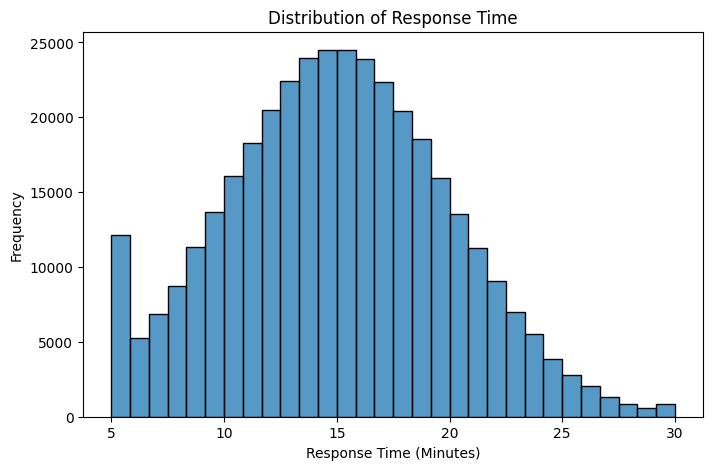

In [59]:
# Histogram of Response Time

plt.figure(figsize=(8,5))

sns.histplot(df["Response_Time"], bins=30)

plt.title("Distribution of Response Time")
plt.xlabel("Response Time (Minutes)")
plt.ylabel("Frequency")

plt.show()

In [64]:
numeric_df = df.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr()

corr_matrix

,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Ambulance_Speed,Fuel_Level,Response_Time
Hospital_Capacity,1.000000,-0.000248,0.000154,0.001037,-0.000120,0.000041
Distance_to_Incident,-0.000248,1.000000,-0.000933,0.000406,0.000424,0.001160
Number_of_Injuries,0.000154,-0.000933,1.000000,-0.001358,-0.001422,0.000678
Ambulance_Speed,0.001037,0.000406,-0.001358,1.000000,-0.002243,-0.000682
Fuel_Level,-0.000120,0.000424,-0.001422,-0.002243,1.000000,0.001737
Response_Time,0.000041,0.001160,0.000678,-0.000682,0.001737,1.000000


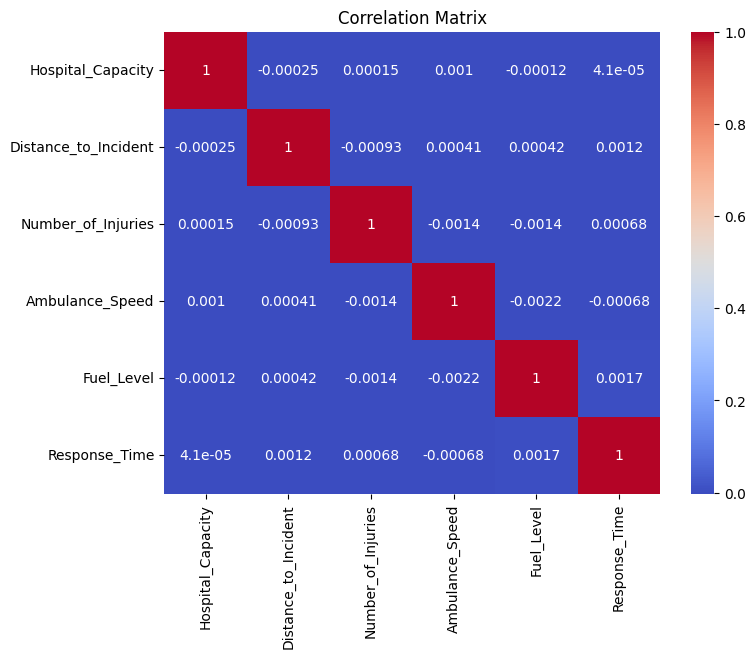

In [69]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()
# The numerical variables exhibit very weak correlations with response time, indicating no strong linear relationships within the dataset.

In [76]:
df["Incident_Type"].value_counts()

Incident_Type
Accident          184114
Cardiac Arrest     73890
Other              73545
Fire               36516
Name: count, dtype: int64

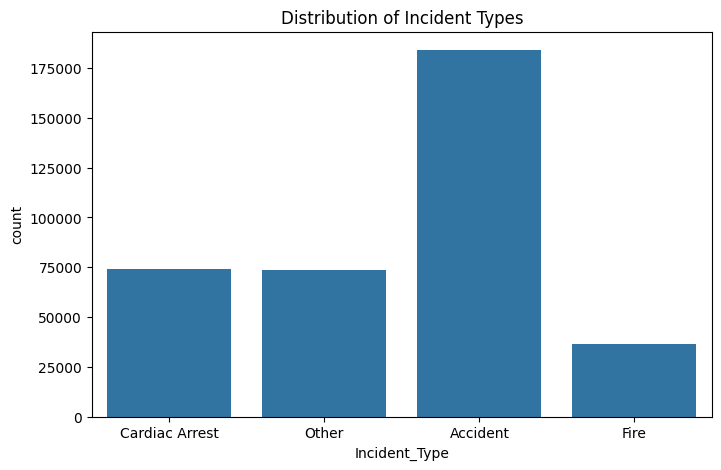

In [70]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Incident_Type",
    data=df
)

plt.title("Distribution of Incident Types")

plt.show()

In [77]:
df["Emergency_Level"].value_counts()

Emergency_Level
Minor       257467
Major        73577
Critical     37021
Name: count, dtype: int64

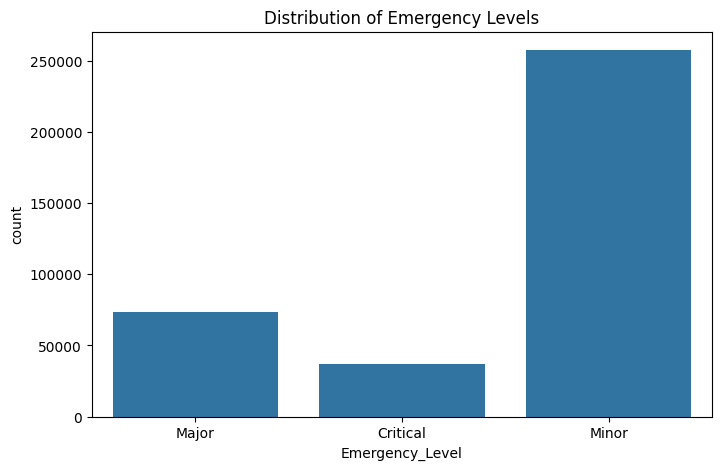

In [71]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Emergency_Level",
    data=df
)

plt.title("Distribution of Emergency Levels")

plt.show()

In [78]:
df["Weather_Condition"].value_counts()

Weather_Condition
Clear     294668
Rainy      55105
Stormy     18292
Name: count, dtype: int64

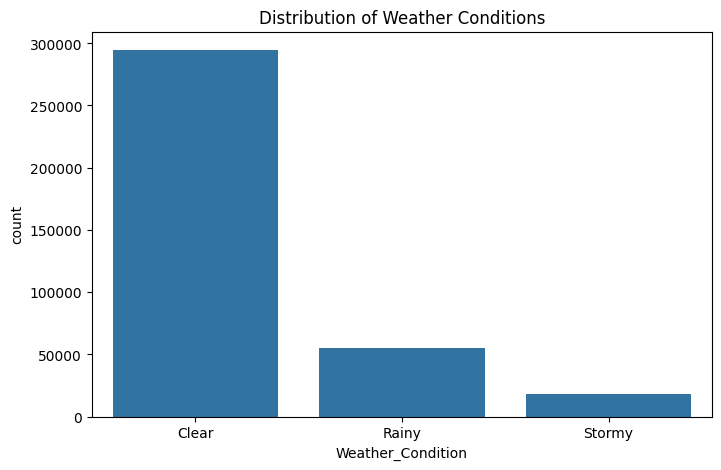

In [72]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Weather_Condition",
    data=df
)

plt.title("Distribution of Weather Conditions")

plt.show()

In [79]:
df["Region_Type"].value_counts()

Region_Type
Urban       257605
Suburban     73811
Rural        36649
Name: count, dtype: int64

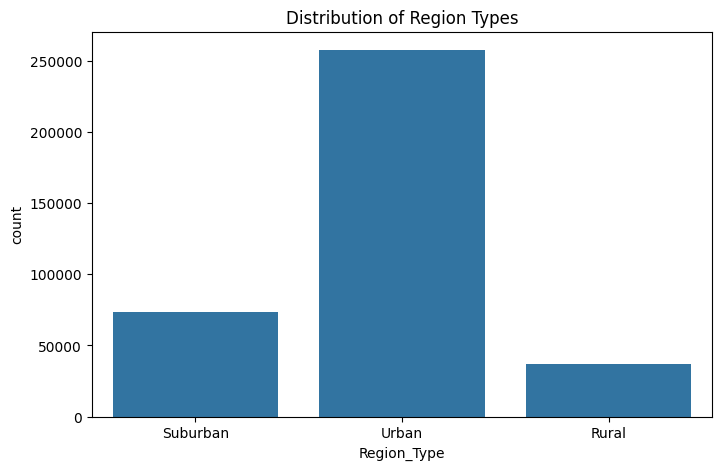

In [73]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Region_Type",
    data=df
)

plt.title("Distribution of Region Types")

plt.show()

In [81]:
df["Ambulance_Availability"].value_counts()

Ambulance_Availability
Available      331345
Unavailable     36720
Name: count, dtype: int64

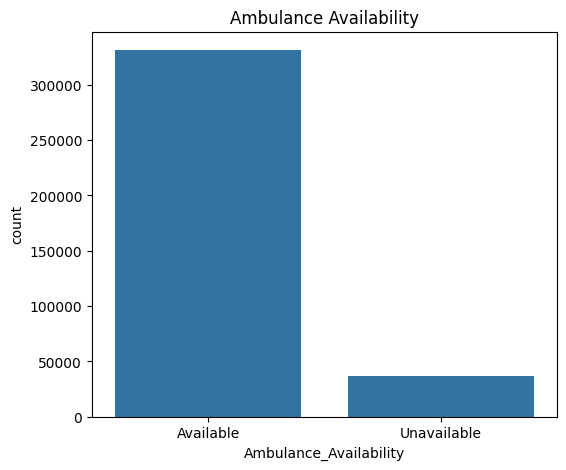

In [74]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="Ambulance_Availability",
    data=df
)

plt.title("Ambulance Availability")

plt.show()

In [82]:
(df["Incident_Type"].value_counts(normalize=True) * 100).round(2)

Incident_Type
Accident          50.02
Cardiac Arrest    20.08
Other             19.98
Fire               9.92
Name: proportion, dtype: float64

In [83]:
(df["Emergency_Level"].value_counts(normalize=True) * 100).round(2)

Emergency_Level
Minor       69.95
Major       19.99
Critical    10.06
Name: proportion, dtype: float64

In [84]:
(df["Region_Type"].value_counts(normalize=True) * 100).round(2)

Region_Type
Urban       69.99
Suburban    20.05
Rural        9.96
Name: proportion, dtype: float64

In [1]:
#The exploratory analysis showed that the dataset contains no missing values or duplicate records.
#Response time is approximately normally distributed around 15 minutes.
#Most incidents are accidents, most emergency levels are minor, and most incidents occur in urban regions under clear weather conditions.